In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
from sklearn.preprocessing import LabelEncoder
warnings.filterwarnings("ignore")

In [15]:
data=pd.read_csv('/home/saurabh/AI_PROJECTS/House_Prediction_project/data.csv')

In [16]:
data.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [6]:
data.shape

(4600, 18)

In [7]:
data.columns

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country'],
      dtype='object')

In [8]:
data.dtypes

date              object
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
street            object
city              object
statezip          object
country           object
dtype: object

In [9]:
data.tail()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
4595,2014-07-09 00:00:00,308166.666667,3.0,1.75,1510,6360,1.0,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,USA
4596,2014-07-09 00:00:00,534333.333333,3.0,2.50,1460,7573,2.0,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,USA
4597,2014-07-09 00:00:00,416904.166667,3.0,2.50,3010,7014,2.0,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,USA
4598,2014-07-10 00:00:00,203400.000000,4.0,2.00,2090,6630,1.0,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,USA
4599,2014-07-10 00:00:00,220600.000000,3.0,2.50,1490,8102,2.0,0,0,4,1490,0,1990,0,18717 SE 258th St,Covington,WA 98042,USA


In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   object 
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   object 
 15  city           4600 non-null   object 
 16  statezip       4600 non-null   object 
 17  country        4600 non-null   object 
dtypes: float

In [11]:
data.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


In [12]:
data.isnull().sum()

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64

In [19]:
# columns=['street', 'city', 'statezip', 'country']
encoding=LabelEncoder()
data["street"]=encoding.fit_transform(data['street'])
data["city"]=encoding.fit_transform(data['city'])
data["statezip"]=encoding.fit_transform(data['statezip'])
data['country']=encoding.fit_transform(data['country'])

In [21]:
data.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,1522,36,62,0
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,3899,35,58,0
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,2291,18,26,0
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,4263,3,7,0
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,4352,31,31,0


In [22]:
data.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,1522,36,62,0
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,3899,35,58,0
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,2291,18,26,0
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,4263,3,7,0
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,4352,31,31,0


## Exploratary Data Analysis

In [23]:
data['date']=pd.to_datetime(data['date']).dt.date

In [24]:
data.tail()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
4595,2014-07-09,308166.666667,3.0,1.75,1510,6360,1.0,0,0,4,1510,0,1954,1979,3447,35,62,0
4596,2014-07-09,534333.333333,3.0,2.50,1460,7573,2.0,0,0,3,1460,0,1983,2009,960,3,6,0
4597,2014-07-09,416904.166667,3.0,2.50,3010,7014,2.0,0,0,3,3010,0,2009,0,4033,32,37,0
4598,2014-07-10,203400.000000,4.0,2.00,2090,6630,1.0,0,0,3,1070,1020,1974,0,3498,35,71,0
4599,2014-07-10,220600.000000,3.0,2.50,1490,8102,2.0,0,0,4,1490,0,1990,0,1514,9,26,0


<Axes: ylabel='Density'>

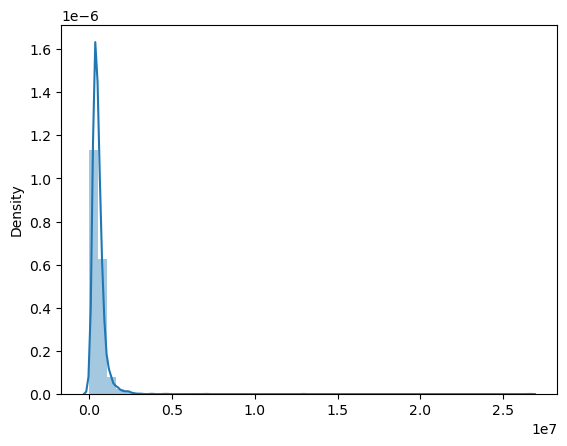

In [25]:
sns.distplot(x=data.price,kde=True)

<Axes: ylabel='Density'>

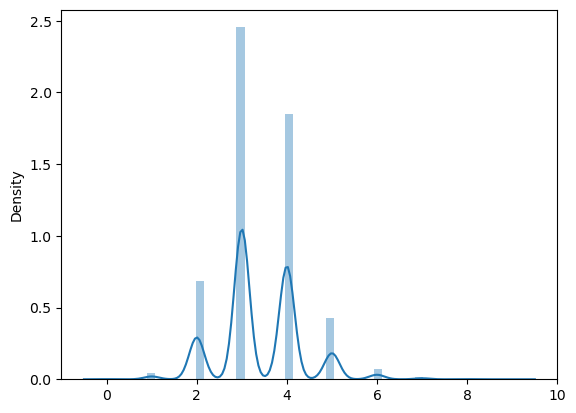

In [26]:
sns.distplot(x=data.bedrooms,kde=True)

<Axes: ylabel='Density'>

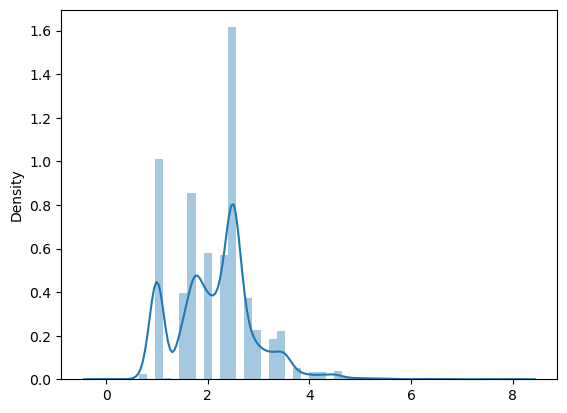

In [27]:
sns.distplot(x=data.bathrooms)

<Axes: ylabel='Density'>

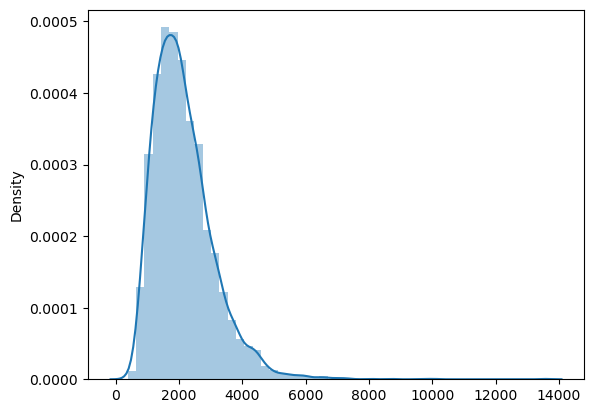

In [28]:
sns.distplot(x=data.sqft_living,kde=True)

In [29]:
data['sqft_living'].skew()

np.float64(1.723513270622118)

<Axes: ylabel='Density'>

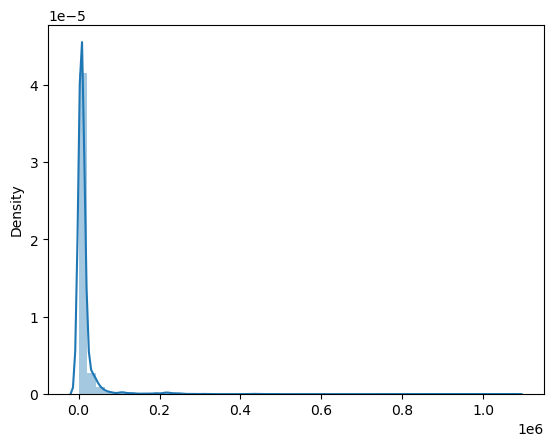

In [30]:
sns.distplot(x=data.sqft_lot,kde=True)

<Axes: ylabel='Density'>

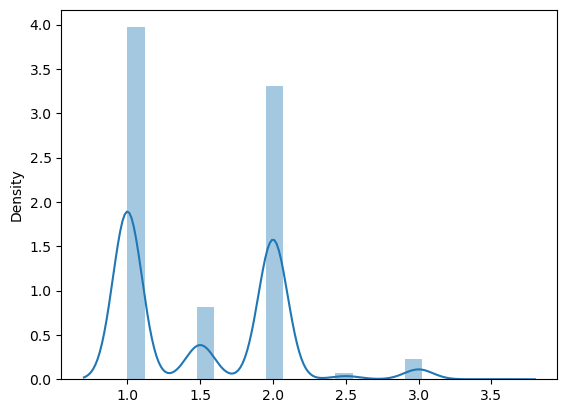

In [31]:
sns.distplot(x=data.floors,kde=True)


<Axes: ylabel='Density'>

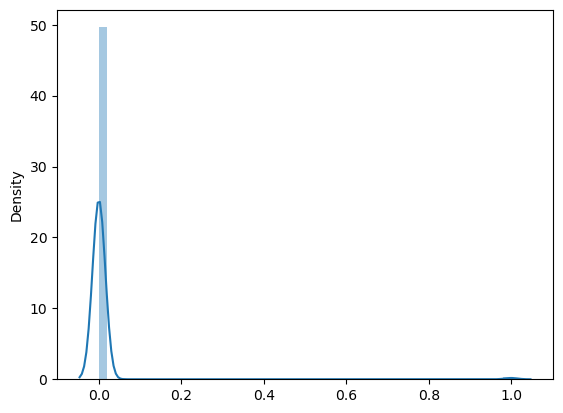

In [32]:
sns.distplot(x=data.waterfront,kde=True)

<Axes: ylabel='Density'>

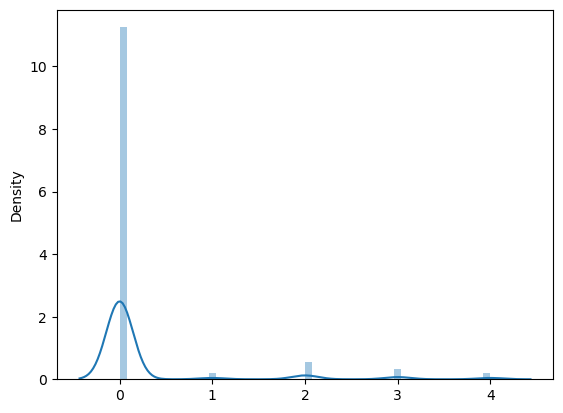

In [33]:
sns.distplot(x=data.view,kde=True)

<Axes: ylabel='Density'>

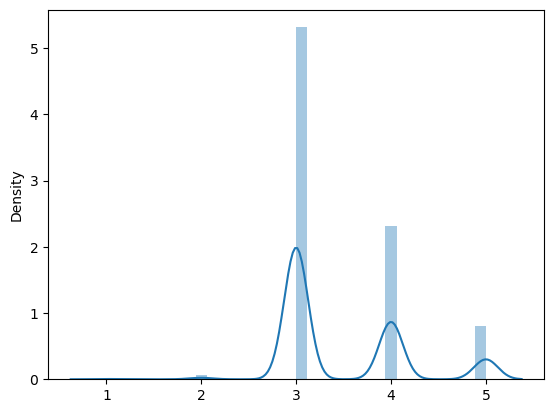

In [34]:
sns.distplot(x=data.condition,kde=True)

<Axes: ylabel='Density'>

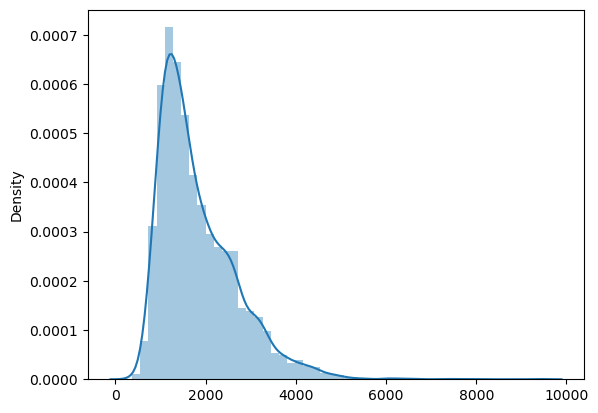

In [35]:
sns.distplot(x=data.sqft_above,kde=True)

In [36]:
data['sqft_above'].skew()

np.float64(1.4942107479829443)

<Axes: ylabel='Density'>

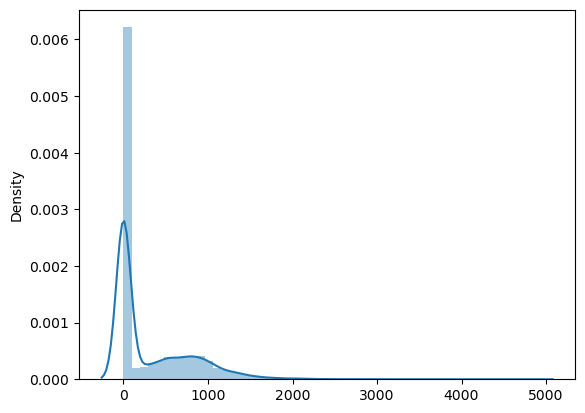

In [37]:
sns.distplot(x=data.sqft_basement,kde=True)

<Axes: ylabel='Density'>

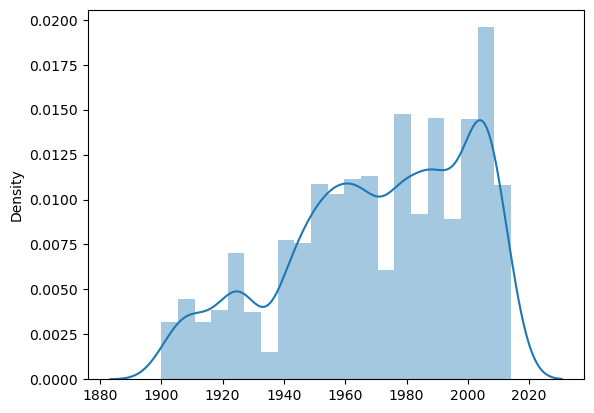

In [38]:

sns.distplot(x=data.yr_built,kde=True)

<Axes: ylabel='Density'>

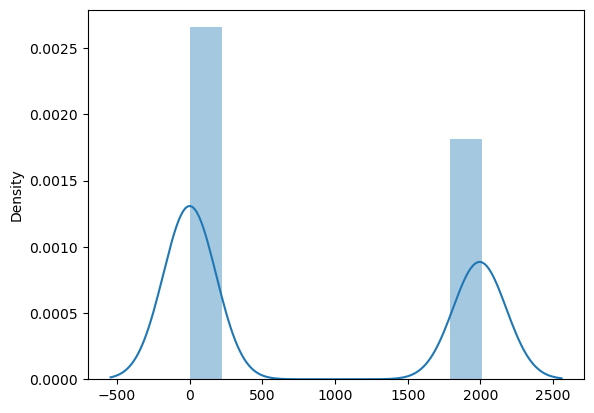

In [39]:
sns.distplot(x=data.yr_renovated,kde=True)

# sns.distplot(x=data.street,kde=True)



<Axes: xlabel='bedrooms', ylabel='price'>

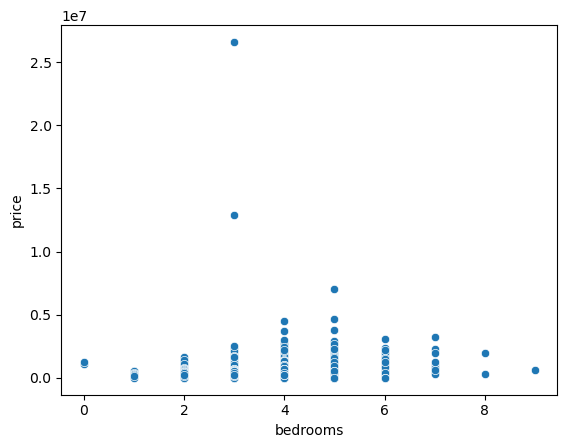

In [40]:
sns.scatterplot(data=data,x='bedrooms',y='price')

<Axes: xlabel='bathrooms', ylabel='price'>

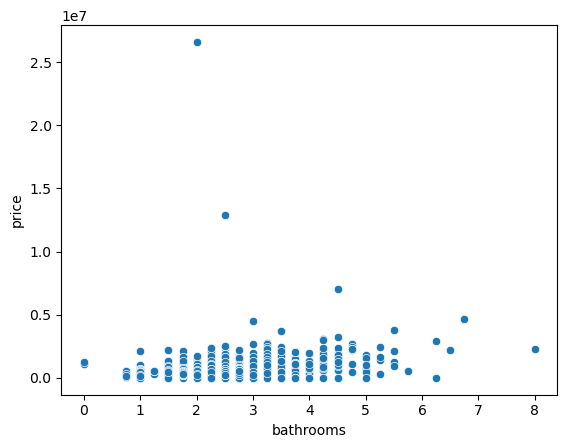

In [41]:
sns.scatterplot(data=data,x='bathrooms',y='price')

<Axes: xlabel='sqft_living', ylabel='price'>

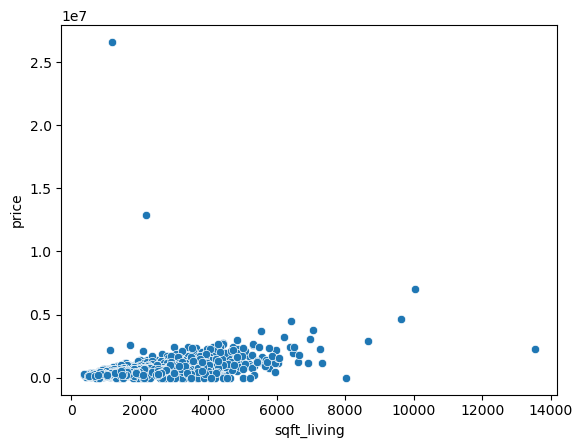

In [42]:
sns.scatterplot(data=data,x='sqft_living',y='price')

<Axes: xlabel='sqft_lot', ylabel='price'>

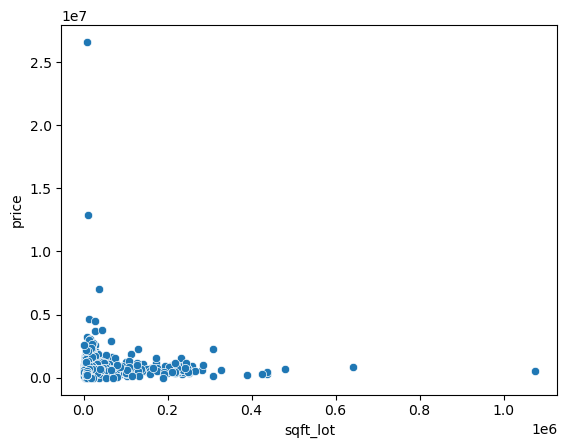

In [43]:
sns.scatterplot(data=data,x='sqft_lot',y='price')

<Axes: xlabel='street', ylabel='price'>

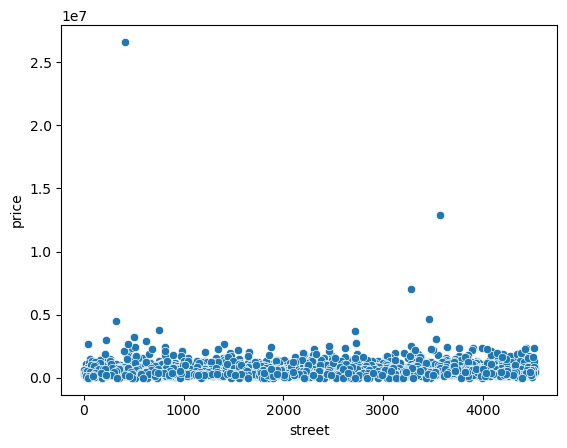

In [45]:
sns.scatterplot(data=data,x='street',y='price')

In [47]:
data.isnull().sum()

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64

In [46]:
data.duplicated().sum()

np.int64(0)

## Outliers

<Axes: xlabel='date'>

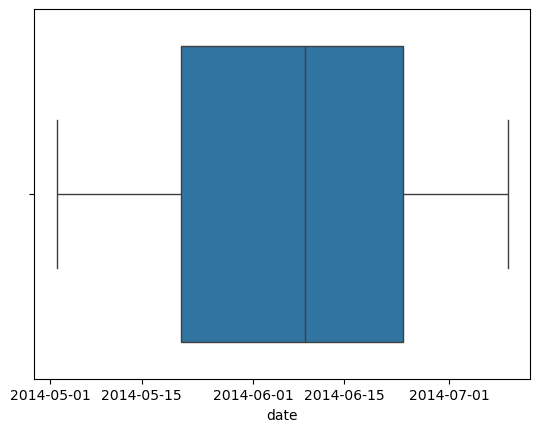

In [48]:
sns.boxplot(x=data.date)

<Axes: xlabel='price'>

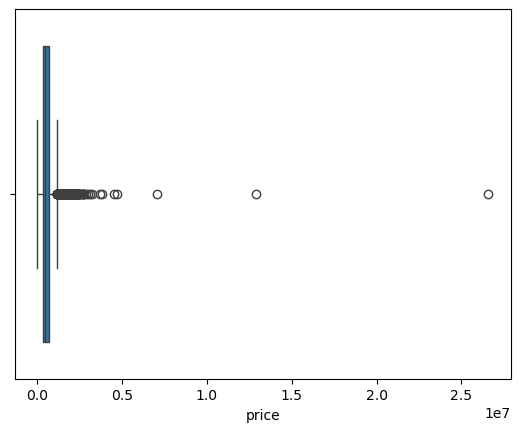

In [49]:
sns.boxplot(x=data.price)

In [50]:
q1=data['price'].quantile(0.25)
q3=data['price'].quantile(0.75)

In [51]:
print("q1 =",q1)

q1 = 322875.0


In [52]:
print("q3 =",q3)

q3 = 654962.5


In [53]:
IQR=q3-q1

In [54]:
print("Iqr = ",IQR)

Iqr =  332087.5


In [55]:
lower_limit=q1-(1.5*IQR)

In [56]:
lower_limit

np.float64(-175256.25)

In [57]:
upper_limit=q3+(1.5*IQR)

In [58]:
upper_limit

np.float64(1153093.75)

In [59]:
data.loc[data['price']>upper_limit]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
1,2014-05-02,2.384000e+06,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,3899,35,58,0
11,2014-05-02,1.400000e+06,4.0,2.50,2920,4000,1.5,0,0,5,1910,1010,1909,1988,3025,35,48,0
14,2014-05-02,1.200000e+06,5.0,2.75,2910,9480,1.5,0,0,3,2910,0,1939,1969,2905,35,48,0
99,2014-05-05,1.395000e+06,5.0,3.50,4010,8510,2.0,0,1,5,2850,1160,1971,0,3058,35,48,0
122,2014-05-05,2.280000e+06,7.0,8.00,13540,307752,3.0,0,4,3,9410,4130,1999,0,2310,31,32,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4348,2014-05-05,2.199900e+06,4.0,1.50,1120,5427,1.0,0,0,3,1120,0,1969,2014,1542,9,26,0
4350,2014-07-03,2.659000e+07,3.0,2.00,1180,7793,1.0,0,0,4,1180,0,1992,0,408,18,19,0
4465,2014-06-05,2.560498e+06,3.0,2.50,1710,1664,2.0,0,0,5,1300,410,2003,0,2462,35,74,0
4467,2014-06-06,1.337044e+06,4.0,3.50,4280,9583,2.0,0,0,3,4280,0,2005,0,832,3,3,0


In [60]:
data.loc[data['price']<lower_limit]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country


In [61]:
len(data.loc[data['price']>upper_limit])/len(data)

0.05217391304347826

<Axes: xlabel='bedrooms'>

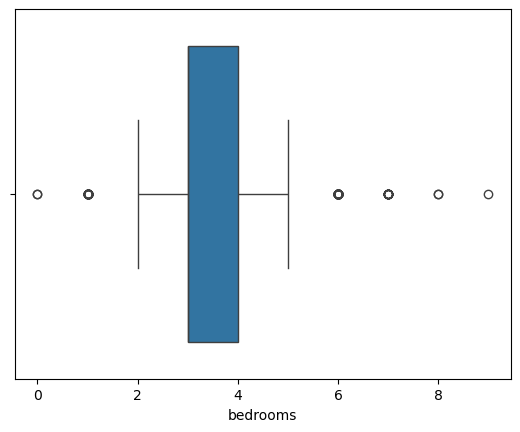

In [62]:
sns.boxplot(x=data.bedrooms)

In [63]:
q1=data['bedrooms'].quantile(0.25)
q3=data['bedrooms'].quantile(0.75)

In [64]:
IQR=q3-q1

In [65]:
IQR

np.float64(1.0)

In [66]:
lower_limit=q1-(1.5*IQR)

In [67]:
upper_limit=q3+(1.5*IQR)

In [68]:
data.loc[data['bedrooms']>upper_limit]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
92,2014-05-05,8.230000e+05,6.0,1.75,2920,5000,2.5,0,0,4,2780,140,1908,0,542,35,59,0
122,2014-05-05,2.280000e+06,7.0,8.00,13540,307752,3.0,0,4,3,9410,4130,1999,0,2310,31,32,0
170,2014-05-06,4.750000e+05,6.0,3.00,3470,117612,1.5,0,0,3,3470,0,1924,2011,1541,17,16,0
241,2014-05-07,5.999990e+05,9.0,4.50,3830,6988,2.5,0,0,3,2450,1380,1938,2003,4293,35,47,0
252,2014-05-07,3.200000e+06,7.0,4.50,6210,8856,2.5,0,2,5,4760,1450,1910,0,499,35,52,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4301,2014-07-10,8.800000e+05,6.0,2.50,2640,3680,2.0,0,0,5,1760,880,1922,1956,2565,35,61,0
4341,2014-05-08,3.750000e+05,6.0,2.25,3206,5793,2.0,0,0,3,3206,0,2012,1912,2255,18,20,0
4357,2014-05-05,0.000000e+00,6.0,2.75,3200,9200,1.0,0,2,4,1600,1600,1953,1983,496,6,65,0
4509,2014-06-18,0.000000e+00,6.0,3.00,3020,13783,2.0,0,0,3,3020,0,1952,2002,3135,23,25,0


In [69]:
data.loc[data['bedrooms']<lower_limit]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
260,2014-05-07,250000.0,1.0,1.00,1100,4373,1.0,0,0,2,820,280,1947,0,1983,6,68,0
477,2014-05-12,235000.0,1.0,1.00,810,2451,1.0,0,0,5,810,0,1941,0,4431,35,61,0
784,2014-05-16,350000.0,1.0,1.00,700,5100,1.0,0,0,3,700,0,1942,1999,3856,35,54,0
831,2014-05-16,540000.0,1.0,1.00,1140,6700,1.5,0,0,3,1140,0,1920,1979,4348,35,47,0
883,2014-05-19,285000.0,1.0,1.50,810,3211,2.0,0,0,4,810,0,1982,2011,377,19,21,0
969,2014-05-20,458000.0,1.0,2.25,2140,10350,1.0,0,0,3,1470,670,1976,0,931,42,41,0
1018,2014-05-20,194000.0,1.0,1.00,820,1060,1.0,0,0,3,760,60,2007,0,3681,35,61,0
1051,2014-05-21,420850.0,1.0,1.00,960,40946,1.0,0,0,5,960,0,1945,0,190,7,10,0
1140,2014-05-22,275000.0,1.0,0.75,1170,14149,1.0,0,0,5,880,290,1962,0,2984,12,12,0
1216,2014-05-22,353000.0,1.0,1.00,550,1279,2.0,0,0,3,550,0,2008,0,1161,35,59,0


In [70]:
len(data.loc[data['bedrooms']>upper_limit])/len(data)

0.016956521739130436

In [71]:
len(data.loc[data['bedrooms']<upper_limit])/len(data)

0.9830434782608696

<Axes: xlabel='bathrooms'>

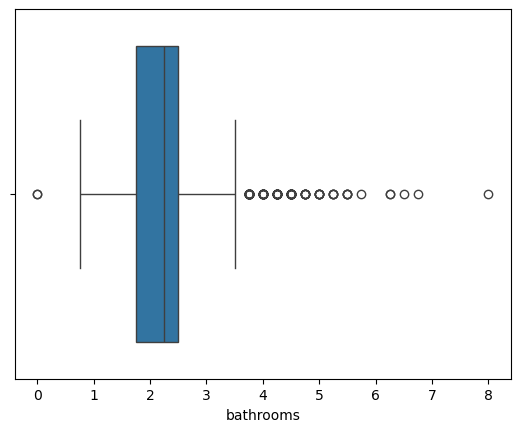

In [72]:
sns.boxplot(x=data.bathrooms)

<Axes: xlabel='sqft_living'>

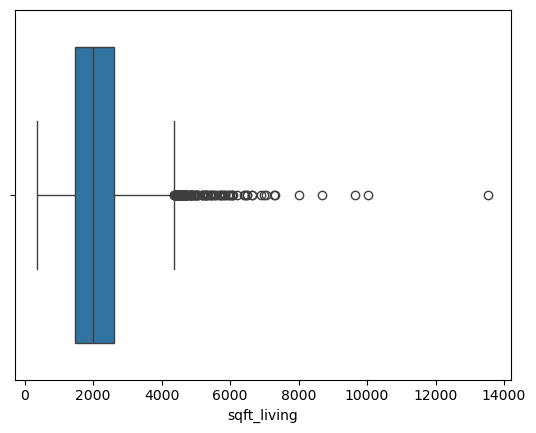

In [73]:
sns.boxplot(x=data.sqft_living)

<Axes: xlabel='street'>

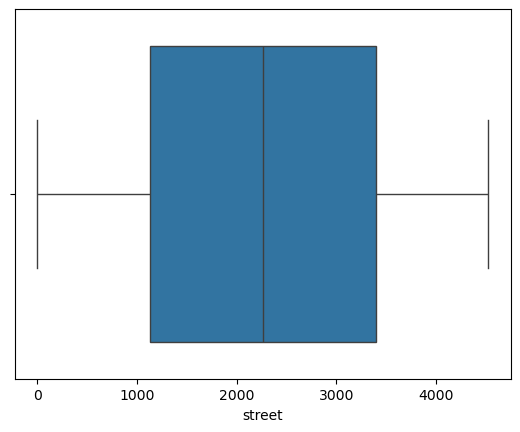

In [76]:
sns.boxplot(x=data['street'])

<Axes: xlabel='city'>

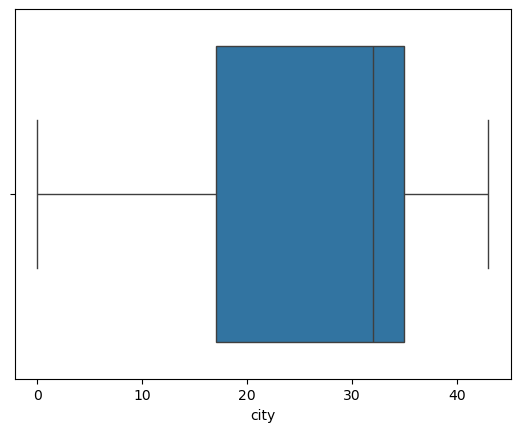

In [98]:
sns.boxplot(x=data.city)

<Axes: xlabel='statezip'>

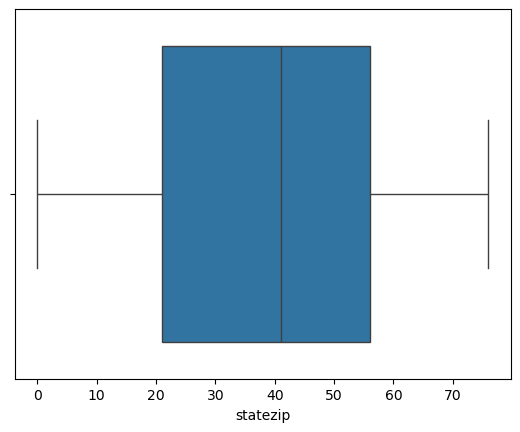

In [99]:
sns.boxplot(x=data.statezip)

<Axes: xlabel='country'>

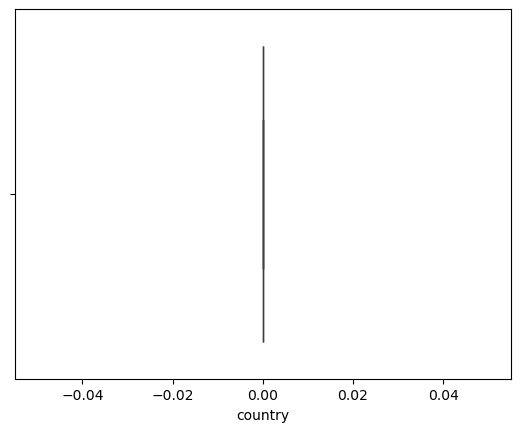

In [100]:
sns.boxplot(x=data.country)

In [77]:
data=data.drop("date",axis=1)

In [78]:
x=data.drop(["price"],axis=1)
y=data["price"]

In [79]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.30,random_state=4)

In [80]:
x_train.shape

(3220, 16)

In [81]:
y_train.shape

(3220,)

In [82]:
x_test.shape

(1380, 16)

In [83]:
from sklearn.linear_model import LinearRegression

In [84]:
model=LinearRegression()

In [85]:
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [86]:
y_pred=model.predict(x_test)
y_pred

array([ 519636.78719188,  734167.77064819,  412913.26226539, ...,
        538112.33692525,  901294.53344239, 1300642.50354334],
      shape=(1380,))

In [87]:
model.coef_

array([-6.12289349e+04,  5.92666527e+04,  1.61592816e+02, -6.60222602e-01,
        1.69203177e+04,  4.43057849e+05,  3.36173927e+04,  3.93576280e+04,
        9.95073438e+01,  6.20854722e+01, -2.19014014e+03,  1.00205578e+01,
       -2.61815687e+00,  3.09543615e+03, -1.36807568e+03,  0.00000000e+00])

In [88]:
model.intercept_

np.float64(4214785.227955006)

In [89]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,root_mean_squared_error,r2_score

In [90]:
#MSE
MSE=mean_squared_error(y_test,y_pred)

In [91]:
MSE

65701161634.77634

In [92]:
#MAE
MAE=mean_absolute_error(y_test,y_pred)

In [93]:
MAE

162360.33328364568

In [94]:
#RMSE
RSME=root_mean_squared_error(y_test,y_pred)

In [95]:
RSME

256322.37833395728

In [96]:
r2_score(y_test,y_pred)

0.5462106677806238

In [97]:
adj_r2=1-(1-0.75)*(60-1)/(60-3-1)
adj_r2

0.7366071428571428